In [21]:
# Imports
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn import metrics
from google.colab import drive

# Connect to Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# Read the Cancer.csv
file_path = '/content/drive/My Drive/Datasets/Cancer.csv'
df = pd.DataFrame(pd.read_csv(file_path))

In [23]:
# Remove the id column and the empty column at the end
df = df.drop(columns=['id', 'Unnamed: 32'])
print('Number of examples m =', len(df))
df.head()

Number of examples m = 569


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [24]:
# Input variables (all 30 features)
X = df.drop(columns='diagnosis').values
# Output: malignant (M) = 1 (positive class), benign (B) = 0
y = df['diagnosis'].map({'M': 1, 'B': 0}).values
print('Malignant:', np.sum(y == 1), '| Benign:', np.sum(y == 0))

Malignant: 212 | Benign: 357


In [25]:
# 80/20 split into training and test set (same split as in Homework 3 and 4)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=100)

In [26]:
# The training set is split again 80/20 into a smaller training set and a validation set
# The validation set is used for the loss/accuracy curves and to choose the network, the test set is only used for the final evaluation
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, train_size=0.8, test_size=0.2, random_state=100)
print('Training examples:', len(y_train), f'({len(y_tr)} for training + {len(y_val)} for validation)',
      '| Test examples:', len(y_test))

Training examples: 455 (364 for training + 91 for validation) | Test examples: 114


In [27]:
# Standardization: scaler is fitted on the training set only and then applied to the other sets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_tr = scaler.transform(X_tr)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

def evaluate(y, y_pred):
    return {'Accuracy': metrics.accuracy_score(y, y_pred),
            'Precision': metrics.precision_score(y, y_pred),
            'Recall': metrics.recall_score(y, y_pred),
            'F1 score': metrics.f1_score(y, y_pred)}

## 2.a) Fully connected neural network

In [28]:
# Convert to PyTorch tensors (labels as class indices for nn.CrossEntropyLoss)
def to_tensor(x, y):
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

train_x, train_y = to_tensor(X_train, y_train)
tr_x, tr_y = to_tensor(X_tr, y_tr)
val_x, val_y = to_tensor(X_val, y_val)
test_x, test_y = to_tensor(X_test, y_test)

In [29]:
# DataLoader for the minibatches (shuffled in every epoch)
batch_size = 16
def make_loader(x, y):
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x, y), batch_size=batch_size, shuffle=True)

In [30]:
# Accuracy = number of correct classifications over the total (like in the lecture)
def accuracy(outputs, labels):
    _, predicted = torch.max(outputs, dim=1)
    return (predicted == labels).sum().item() / len(labels)

In [31]:
# Training loop from the lecture with minibatches, loss and accuracy per epoch
# (without validation data the curves are not recorded)
def training_loop(n_epochs, optimizer, model, loss_fn, train_x, train_y, val_x=None, val_y=None):
    train_loader = make_loader(train_x, train_y)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(1, n_epochs + 1):
        model.train()
        for x_batch, y_batch in train_loader:
            outputs = model(x_batch)
            loss = loss_fn(outputs, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Loss and accuracy on the whole training and validation set after every epoch
        if val_x is not None:
            model.eval()
            with torch.no_grad():
                train_out = model(train_x)
                val_out = model(val_x)
                history['train_loss'].append(loss_fn(train_out, train_y).item())
                history['val_loss'].append(loss_fn(val_out, val_y).item())
                history['train_acc'].append(accuracy(train_out, train_y))
                history['val_acc'].append(accuracy(val_out, val_y))
            if epoch == 1 or epoch % 20 == 0:
                print(f'Epoch {epoch}, Training loss {history["train_loss"][-1]:.4f}, '
                      f'Validation loss {history["val_loss"][-1]:.4f}, '
                      f'Training accuracy {history["train_acc"][-1]:.4f}, Validation accuracy {history["val_acc"][-1]:.4f}')
    return history

In [32]:
# Small experiment with different hidden layer sizes and activation functions
# 2 output neurons (benign, malignant) and nn.CrossEntropyLoss like in the lecture
def build_model(h1, h2, activation):
    return nn.Sequential(
        nn.Linear(30, h1),
        activation(),
        nn.Linear(h1, h2),
        activation(),
        nn.Linear(h2, 2))

def predict(model, x):
    with torch.no_grad():
        return torch.max(model(x), dim=1)[1].numpy()

configs = [(16, 8, nn.ReLU), (32, 16, nn.ReLU), (64, 32, nn.ReLU), (32, 16, nn.Tanh)]
learning_rate = 1e-2
n_epochs = 100
nn_results = {}

for h1, h2, activation in configs:
    name = f'30-{h1}-{h2}-2 {activation.__name__}'
    print(f'\n--- {name} ---')
    torch.manual_seed(0)  # same start weights and batch order for every run
    model = build_model(h1, h2, activation)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate)
    history = training_loop(n_epochs, optimizer, model, nn.CrossEntropyLoss(), tr_x, tr_y, val_x, val_y)

    n_params = sum(p.numel() for p in model.parameters())
    nn_results[name] = {'config': (h1, h2, activation), 'history': history, 'params': n_params,
                        **evaluate(y_val, predict(model, val_x))}

print('\nValidation results:')
for name, r in nn_results.items():
    print(f"{name:<17} | parameters={r['params']:<5} | accuracy={r['Accuracy']:.4f} | precision={r['Precision']:.4f} "
          f"| recall={r['Recall']:.4f} | F1={r['F1 score']:.4f} | val loss={r['history']['val_loss'][-1]:.4f}")


--- 30-16-8-2 ReLU ---
Epoch 1, Training loss 0.7101, Validation loss 0.7151, Training accuracy 0.3214, Validation accuracy 0.3077
Epoch 20, Training loss 0.1835, Validation loss 0.1870, Training accuracy 0.9423, Validation accuracy 0.9341
Epoch 40, Training loss 0.0824, Validation loss 0.0861, Training accuracy 0.9863, Validation accuracy 0.9780
Epoch 60, Training loss 0.0623, Validation loss 0.0710, Training accuracy 0.9863, Validation accuracy 0.9780
Epoch 80, Training loss 0.0542, Validation loss 0.0720, Training accuracy 0.9890, Validation accuracy 0.9780
Epoch 100, Training loss 0.0489, Validation loss 0.0815, Training accuracy 0.9890, Validation accuracy 0.9670

--- 30-32-16-2 ReLU ---
Epoch 1, Training loss 0.6659, Validation loss 0.6600, Training accuracy 0.6401, Validation accuracy 0.6593
Epoch 20, Training loss 0.1623, Validation loss 0.1729, Training accuracy 0.9505, Validation accuracy 0.9341
Epoch 40, Training loss 0.0792, Validation loss 0.0932, Training accuracy 0.9808

In [33]:
# Selected network = highest validation accuracy (the first/smaller network if two are equal)
best_name = max(nn_results, key=lambda n: nn_results[n]['Accuracy'])
best = nn_results[best_name]
print('\nSelected network:', best_name)


Selected network: 30-64-32-2 ReLU


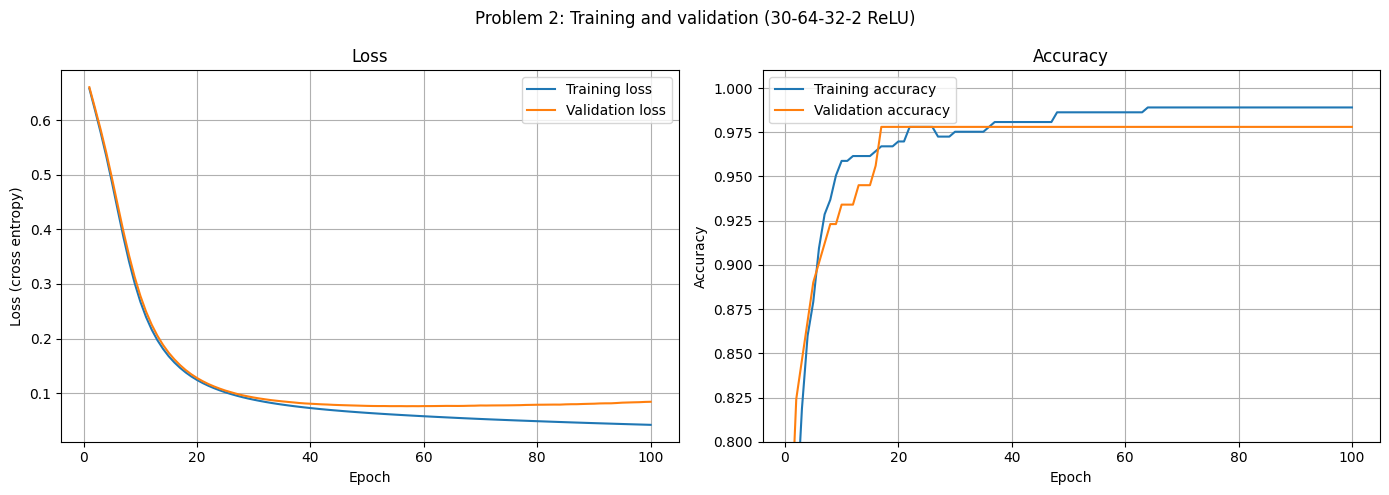

In [34]:
# Plot training and validation loss and accuracy of the selected network
epochs = range(1, n_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs, best['history']['train_loss'], label='Training loss')
axes[0].plot(epochs, best['history']['val_loss'], label='Validation loss')
axes[0].set_ylabel('Loss (cross entropy)')
axes[0].set_title('Loss')
axes[1].plot(epochs, best['history']['train_acc'], label='Training accuracy')
axes[1].plot(epochs, best['history']['val_acc'], label='Validation accuracy')
axes[1].set_ylim(0.8, 1.01)
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()
fig.suptitle(f'Problem 2: Training and validation ({best_name})')
plt.tight_layout()
plt.savefig('problem_2_training.png', dpi=110)
plt.show()

In [35]:
# Final model: the selected network is trained again on the whole training set (80%),
# so it uses the same training data as the logistic regression and the SVM
torch.manual_seed(0)
final_model = build_model(*best['config'])
print(final_model)
optimizer = optim.SGD(final_model.parameters(), lr=learning_rate)
training_loop(n_epochs, optimizer, final_model, nn.CrossEntropyLoss(), train_x, train_y)
y_pred_nn = predict(final_model, test_x)
print('Neural network on the test set:', {k: round(v, 4) for k, v in evaluate(y_test, y_pred_nn).items()},
      '| training accuracy:', round(metrics.accuracy_score(y_train, predict(final_model, train_x)), 4))

Sequential(
  (0): Linear(in_features=30, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)
Neural network on the test set: {'Accuracy': 0.9737, 'Precision': 1.0, 'Recall': 0.9388, 'F1 score': 0.9684} | training accuracy: 0.9912


## 2.b) Comparison with logistic regression and SVM

In [36]:
# Logistic regression
classifier = LogisticRegression(random_state=0)
classifier.fit(X_train, y_train)
y_pred_lr = classifier.predict(X_test)

In [37]:
# SVM: kernel and C are chosen with 5-fold cross-validation on the training set (like in Homework 4)
grid = GridSearchCV(SVC(), {'kernel': ['linear', 'poly', 'rbf'], 'C': [0.01, 0.1, 1, 10, 100]}, cv=5)
grid.fit(X_train, y_train)
print('Best SVM:', grid.best_params_)
y_pred_svm = grid.best_estimator_.predict(X_test)

Best SVM: {'C': 1, 'kernel': 'rbf'}


In [38]:
# Compare all three models on the test set
predictions = {'Logistic regression': y_pred_lr,
               f"SVM ({grid.best_params_['kernel']}, C={grid.best_params_['C']})": y_pred_svm,
               f'Neural network ({best_name})': y_pred_nn}
comparison = pd.DataFrame({name: evaluate(y_test, y_pred) for name, y_pred in predictions.items()}).T
print(comparison.round(4).to_string())

                                  Accuracy  Precision  Recall  F1 score
Logistic regression                 0.9737     1.0000  0.9388    0.9684
SVM (rbf, C=1)                      0.9649     0.9787  0.9388    0.9583
Neural network (30-64-32-2 ReLU)    0.9737     1.0000  0.9388    0.9684


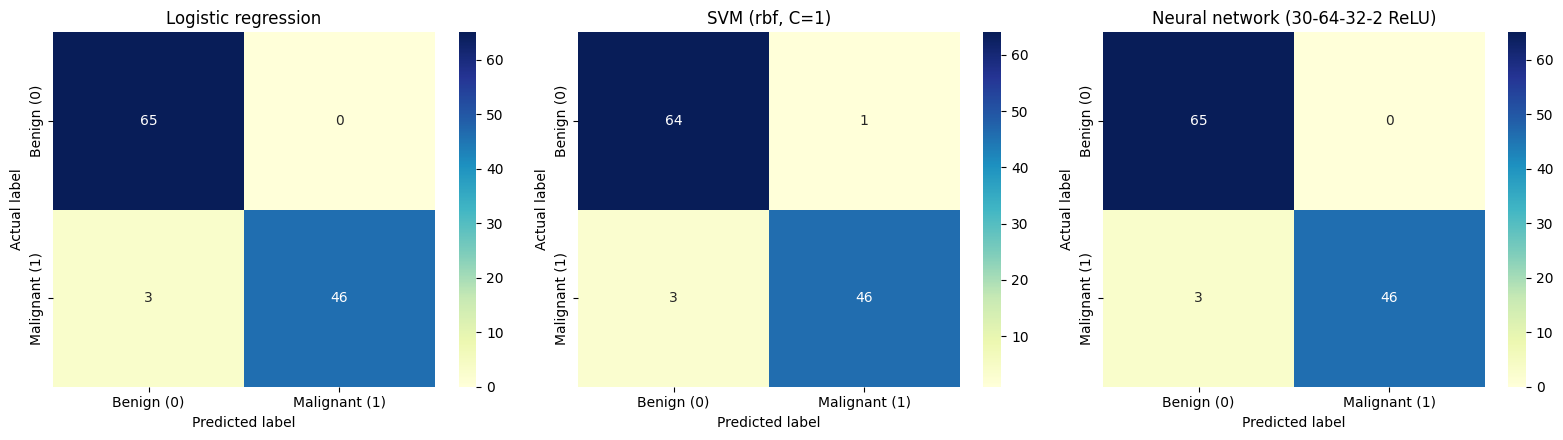

In [39]:
# Confusion matrix for all three models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
    sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap='YlGnBu', fmt='g', ax=ax,
                xticklabels=['Benign (0)', 'Malignant (1)'], yticklabels=['Benign (0)', 'Malignant (1)'])
    ax.set_title(name)
    ax.set_ylabel('Actual label')
    ax.set_xlabel('Predicted label')
plt.tight_layout()
plt.savefig('problem_2_confusion_matrices.png', dpi=110)
plt.show()

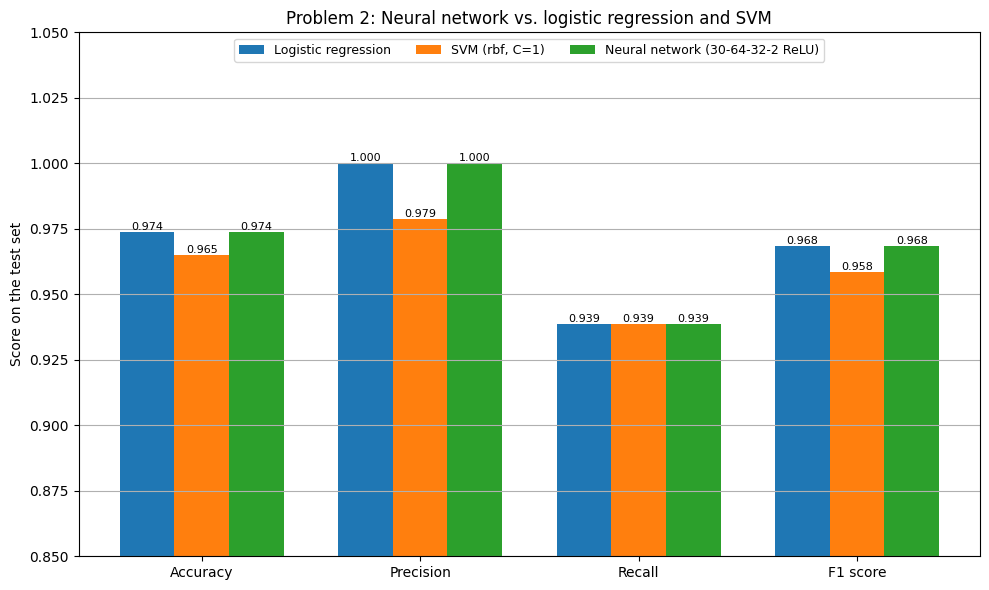

In [40]:
# Bar plot of accuracy, precision, recall and F1 score for all three models
x = np.arange(len(comparison.columns))
width = 0.25
plt.figure(figsize=(10, 6))
for i, name in enumerate(comparison.index):
    bars = plt.bar(x + (i - 1) * width, comparison.loc[name], width, label=name)
    plt.bar_label(bars, fmt='%.3f', fontsize=8)
plt.xticks(x, comparison.columns)
plt.ylim(0.85, 1.05)
plt.ylabel('Score on the test set')
plt.title('Problem 2: Neural network vs. logistic regression and SVM')
plt.grid(True, axis='y')
plt.legend(loc='upper center', ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig('problem_2_scores.png', dpi=110)
plt.show()